In [104]:
import statistics as st
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("autolevante_visitas_limpio.csv", sep=";")
#
nulos = pd.DataFrame({
    "Nulos": df.isna().sum(),
    "% del total": (df.isna().mean() * 100).round(1),
})

nulos[nulos["Nulos"] > 0].sort_values("Nulos", ascending=False)

#Con esto podemos observar que la descripcion es un valor inutil ya que esta el 60 % del campo nulo
#Aparte de que no nos dice nada la descripcion
#Fecha de ultima revision es un tema a debate por su falta de contenido , pero su importancia
#Los Km y la gravedad podemos recrear esos datos usando la media , moda , etc..





,Nulos,% del total
descripcion_averia,960,60.0
fecha_ultima_revision,608,38.0
km,158,9.9
combustible,48,3.0
gravedad,16,1.0


In [105]:
descripcion_averia = df["descripcion_averia"].dropna()
print(f"Hay descripcion en : {len(descripcion_averia)} de {len(df)}")

#Con esto sabemos a mayor exactitud

Hay descripcion en : 640 de 1600


/tmp/ipykernel_1407/2153435282.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_1407/2153435282.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


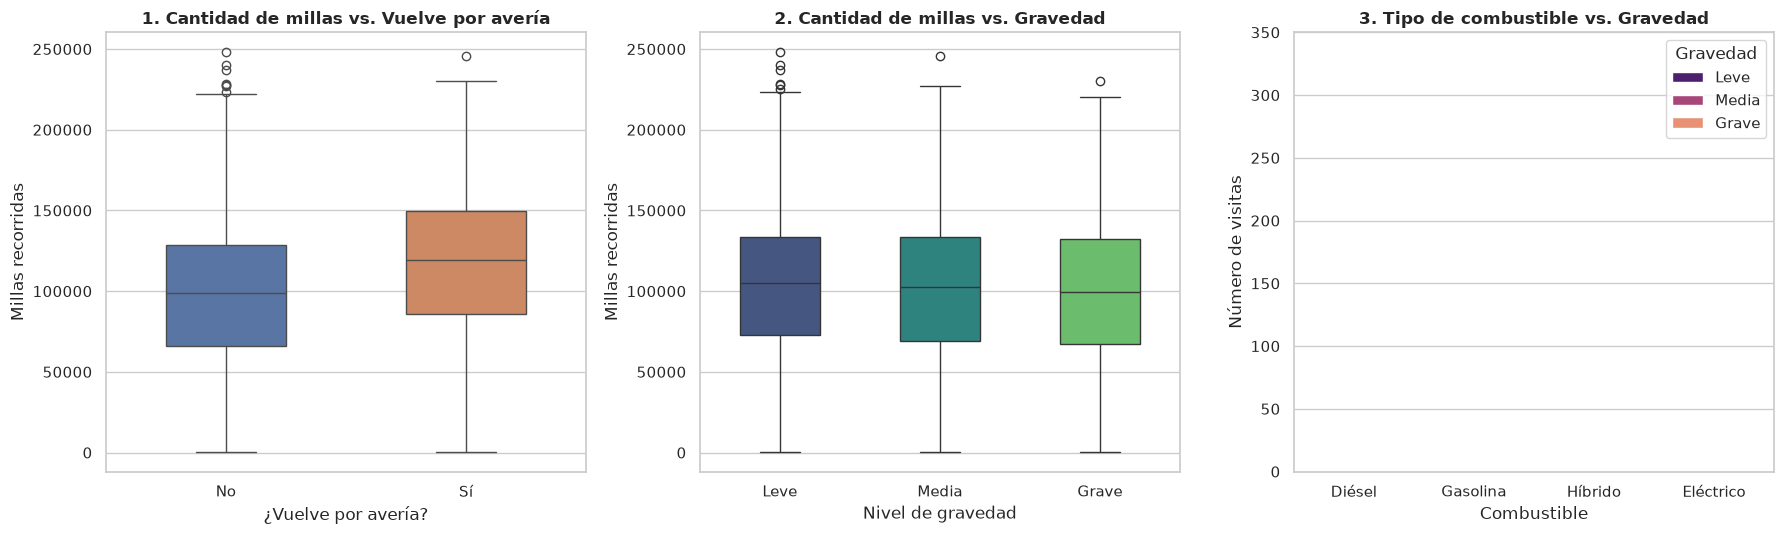

In [106]:
# Configuración general de la figura (1 fila, 3 columnas)
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

orden_gravedad = ["Leve", "Media", "Grave"]

# ---------------------------------------------------------
# 1. Cantidad de millas x Vuelve a avería (Boxplot)
# ---------------------------------------------------------
sns.boxplot(
    data=df,
    x="vuelve_averia",
    y="millas",
    order=["No", "Sí"],
    palette=["#4C72B0", "#DD8452"],
    width=0.5,
    ax=axes[0]
)
axes[0].set_title("1. Cantidad de millas vs. Vuelve por avería", fontweight="bold")
axes[0].set_xlabel("¿Vuelve por avería?")
axes[0].set_ylabel("Millas recorridas")

# ---------------------------------------------------------
# 2. Cantidad de millas x Gravedad (Boxplot)
# ---------------------------------------------------------
sns.boxplot(
    data=df,
    x="gravedad",
    y="millas",
    order=orden_gravedad,
    palette="viridis",
    width=0.5,
    ax=axes[1]
)
axes[1].set_title("2. Cantidad de millas vs. Gravedad", fontweight="bold")
axes[1].set_xlabel("Nivel de gravedad")
axes[1].set_ylabel("Millas recorridas")

# ---------------------------------------------------------
# 3. Combustible x Gravedad (Countplot agrupado)
# ---------------------------------------------------------
sns.countplot(
    data=df,
    x="combustible",
    hue="gravedad",
    order=["Diésel", "Gasolina", "Híbrido", "Eléctrico"],
    hue_order=orden_gravedad,
    palette="magma",
    ax=axes[2]
)
axes[2].set_title("3. Tipo de combustible vs. Gravedad", fontweight="bold")
axes[2].set_xlabel("Combustible")
axes[2].set_ylabel("Número de visitas")
axes[2].legend(title="Gravedad")

# Añadir los números encima de cada barra en la 3ª gráfica
for container in axes[2].containers:
    axes[2].bar_label(container, fontsize=9, padding=2)
axes[2].set_ylim(0, 350)

plt.tight_layout()
plt.show()

Se puede ver bien representado arriba que el nivel de gravedad en funcion de las millas no es una biena relación , ya que las 3 cajas estan a la misma altura , en cambio cuando lo comparamos si vuelven por una avería , vemos claramente que los que vuelven tienen mas millas .


Y en la ultima se ve claramente que esta directamente relacionado el tipo de combistible con la gravedad de la reparación.


Tambien gracias a estos datos nos hemos podido dar cuenta de que el CSV no esta normalizado y faltan datos , sobre todo con el tipo de combustible.



In [107]:
#from google.colab import files

# 1. Guardamos el DataFrame modificado en un nuevo archivo CSV
# Usamos index=False para que Pandas no añada una columna extra con los números de fila (0, 1, 2...)
#df.to_csv("autolevante_visitas_limpio.csv", sep=";", index=False, encoding="utf-8")

# 2. Forzamos la descarga directa a tu ordenador
#files.download("autolevante_visitas_limpio.csv")

df["combustible"]

#Como se puede ver hay muchisimos tipos de combistible :
#Claramente al haber hecho la limpieza y volver a ejecutar este codigo lo que ha sucedido es que sale en buen formato


0         hibrido
1        gasolina
2       electrico
3         hibrido
4             NaN
          ...    
1595       diesel
1596     gasolina
1597    electrico
1598     gasolina
1599       diesel
Name: combustible, Length: 1600, dtype: str

In [108]:
# 1. Quitamos espacios, ponemos solo la primera letra en mayúscula y pasamos 'N/d' a nulo (NaN)
df["combustible"] = (
    df["combustible"]
    .str.strip()                                 # 1. Quita espacios al inicio y al final
    .str.lower()                                 # 2. Pasa todo a minúsculas
    .replace("n/d", np.nan)                      # 3. Convierte 'n/d' en nulo (NaN)
    .str.normalize("NFKD")                       # 4. Separa las letras de sus tildes
    .str.encode("ascii", errors="ignore")        # 5. Elimina las tildes
    .str.decode("utf-8")                         # 6. Devuelve el texto limpio en UTF-8
)

df["combustible"].value_counts(dropna=False)
df["combustible"].value_counts(dropna=False)




combustible
diesel       678
gasolina     548
hibrido      252
electrico     74
NaN           48
Name: count, dtype: int64

In [109]:
# Contamos cuántas veces sale cada matrícula
conteo = df["matricula"].value_counts()

# Creamos una tabla sencilla comparando Únicas vs Repetidas
resumen_matriculas = pd.DataFrame({
    "Grupo": ["No se repiten (1 vez)", "Se repiten (2 a 7 veces)", "TOTAL"],
    "Nº de matrículas": [
        (conteo == 1).sum(),
        (conteo > 1).sum(),
        df["matricula"].nunique()
    ],
    "Filas que ocupan en el CSV": [
        conteo[conteo == 1].sum(),
        conteo[conteo > 1].sum(),
        len(df)
    ]
})

resumen_matriculas["% de matrículas"] = (resumen_matriculas["Nº de matrículas"] / df["matricula"].nunique() * 100).round(1)
resumen_matriculas

,Grupo,Nº de matrículas,Filas que ocupan en el CSV,% de matrículas
0,No se repiten (1 vez),268,268,35.8
1,Se repiten (2 a 7 veces),480,1332,64.2
2,TOTAL,748,1600,100.0


In [110]:
#MATRICULAS
#df_solo_repetidas_distinto_coche = df[
#    df["matricula"].isin(tabla_diferentes_coches["matricula"])
#].sort_values(["matricula", "fecha_entrada"])

#display(df_solo_repetidas_distinto_coche[["matricula", "id_visita", "marca", "modelo", "anyo_matriculacion", "combustible", "fecha_entrada"]].head(20))

In [ ]:
#DESCRIPCION

import numpy as np
import pandas as pd

# 1. Creamos una variable que indique si tiene o no descripción
df["tiene_descripcion"] = np.where(
    df["descripcion_averia"].isna(),
    "Sin descripción (Nulo)",
    "Con descripción"
)

# 2. TABLA 1: Comportamiento frente al objetivo (Con vs Sin descripción)
conteo = pd.crosstab(df["tiene_descripcion"], df["vuelve_averia"])
porcentaje = (pd.crosstab(df["tiene_descripcion"], df["vuelve_averia"], normalize="index") * 100).round(2)

tabla_justificacion = pd.DataFrame({
    "Total visitas": conteo["No"] + conteo["Sí"],
    "No vuelven": conteo["No"],
    "Sí vuelven": conteo["Sí"],
    "% No vuelven": porcentaje["No"],
    "% Sí vuelven (Objetivo)": porcentaje["Sí"]
})
display(tabla_justificacion)

# 3. TABLA 2: Desglose por cada síntoma concreto frente a los nulos
df["desc_con_nulos"] = df["descripcion_averia"].fillna("Sin descripción (Nulo)")
conteo_det = pd.crosstab(df["desc_con_nulos"], df["vuelve_averia"])
pct_det = (pd.crosstab(df["desc_con_nulos"], df["vuelve_averia"], normalize="index") * 100).round(1)

tabla_sintomas = pd.DataFrame({
    "Total visitas": conteo_det["No"] + conteo_det["Sí"],
    "No vuelven": conteo_det["No"],
    "Sí vuelven": conteo_det["Sí"],
    "% Sí vuelven (Objetivo)": pct_det["Sí"]
}).sort_values("Total visitas", ascending=False)
display(tabla_sintomas)

# 4. Una vez demostrado que no hay diferencia, eliminamos la columna original y las auxiliares
df = df.drop(columns=["descripcion_averia", "tiene_descripcion", "desc_con_nulos"])

,Total visitas,No vuelven,Sí vuelven,% No vuelven,% Sí vuelven (Objetivo)
tiene_descripcion,,,,,
Con descripción,640,518,122,80.94,19.06
Sin descripción (Nulo),960,772,188,80.42,19.58


,Total visitas,No vuelven,Sí vuelven,% Sí vuelven (Objetivo)
desc_con_nulos,,,,
Sin descripción (Nulo),960,772,188,19.6
Batería descargada,128,99,29,22.7
Ruido en suspensión delantera,113,98,15,13.3
Pérdida de aceite,106,86,20,18.9
Testigo de motor encendido,104,85,19,18.3
Frenos chirrían,97,80,17,17.5
Embrague patina,92,70,22,23.9


In [ ]:
# 2. Eliminar filas donde 'combustible' sea nulo (NaN) o esté vacío
df = df.dropna(subset=['combustible'])
df = df[df['combustible'].astype(str).str.strip() != '']

# 3. Definir las columnas marcadas/tachadas en la lista para eliminar
columnas_a_eliminar = [
    'matricula', 
    'modelo', 
    'anyo_matriculacion',  
    'km', 
    'taller', 
    'mecanico', 
    'moneda', 
    'descripcion_averia'
]

# Eliminar las columnas (errors='ignore' evita fallos si alguna ya no existe)
df_limpio = df.drop(columns=columnas_a_eliminar, errors='ignore')

In [ ]:
import pandas as pd
import numpy as np

# 0. Tratamos las fechas vacías como valores nulos
df["fecha_ultima_revision"] = df["fecha_ultima_revision"].replace(
    r'^\s*$', np.nan, regex=True
)

# 1. Creamos una variable que indique si tiene o no fecha
df["tiene_fecha_revision"] = np.where(
    df["fecha_ultima_revision"].isna(),
    "Sin fecha (Nulo)",
    "Con fecha"
)

# 2. TABLA 1: Comportamiento frente al objetivo (Con vs Sin fecha)
conteo = pd.crosstab(
    df["tiene_fecha_revision"],
    df["vuelve_averia"]
)

porcentaje = (
    pd.crosstab(
        df["tiene_fecha_revision"],
        df["vuelve_averia"],
        normalize="index"
    ) * 100
).round(2)

tabla_justificacion = pd.DataFrame({
    "Total visitas": conteo["No"] + conteo["Sí"],
    "No vuelven": conteo["No"],
    "Sí vuelven": conteo["Sí"],
    "% No vuelven": porcentaje["No"],
    "% Sí vuelven (Objetivo)": porcentaje["Sí"]
})

display(tabla_justificacion)

#
#Podemos ver que la fecha de ultima revision no tiene relevancia en el objetivo , por lo que podemos eliminarla
#Pero el cliente nos ha pedido que la mantengamos , por lo que la mantendremos
#
#


,Total visitas,No vuelven,Sí vuelven,% No vuelven,% Sí vuelven (Objetivo)
tiene_fecha_revision,,,,,
Con fecha,935,784,151,83.85,16.15
Sin fecha (Nulo),568,424,144,74.65,25.35


In [125]:


# 2. CALCULAR KM Y DETECTAR OUTLIERS
df['km_calc'] = df['millas'] / 0.6214
df['anyo_entrada'] = pd.to_datetime(df['fecha_entrada']).dt.year

cond_1900 = df['anyo_matriculacion'] == 1900
cond_2030 = df['anyo_matriculacion'] == 2030
cond_despues = (df['anyo_matriculacion'] > df['anyo_entrada']) & (~cond_2030)
cond_coherentes = ~(cond_1900 | cond_2030 | cond_despues)

# 3. DIBUJAR LA GRÁFICA
df['x_plot'] = np.where(df['anyo_matriculacion'] == 1900, 2000,
               np.where(df['anyo_matriculacion'] == 2030, 2028, df['anyo_matriculacion']))

fig, ax = plt.subplots(figsize=(9, 6), dpi=120)

df_coh = df[cond_coherentes]
ax.scatter(df_coh['x_plot'], df_coh['km_calc'], color='#8c9ba5', alpha=0.6, s=20, label=f'Coherentes · {len(df_coh)}')
ax.scatter(df[cond_1900]['x_plot'], df[cond_1900]['km_calc'], color='#d62728', edgecolors='black', s=45, zorder=4, label=f'Año 1900 · {cond_1900.sum()}')
ax.scatter(df[cond_2030]['x_plot'], df[cond_2030]['km_calc'], color='#9467bd', edgecolors='black', s=45, zorder=4, label=f'Año 2030 · {cond_2030.sum()}')
ax.scatter(df[cond_despues]['x_plot'], df[cond_despues]['km_calc'], color='#ff7f0e', edgecolors='black', s=45, zorder=4, label=f'Matriculado después de la entrada · {cond_despues.sum()}')

m, b = np.polyfit(df_coh['anyo_matriculacion'], df_coh['km_calc'], 1)
x_line = np.linspace(2005, 2025, 100)
ax.plot(x_line, m * x_line + b, color='black', linestyle='--', linewidth=1.2, label='Tendencia año ↔ km (correctos)')

ax.axvline(x=2001.5, color='#b0b0b0', linestyle='-', linewidth=1)
ax.axvline(x=2026.5, color='#b0b0b0', linestyle='-', linewidth=1)
ax.set_xticks([2000, 2005, 2010, 2015, 2020, 2025, 2028])
ax.set_xticklabels(['1900', '2005', '2010', '2015', '2020', '2025', '2030'])

# Etiquetas del eje Y directas (sin usar ticker)
ax.set_yticks([0, 100000, 200000, 300000, 400000])
ax.set_yticklabels(['0', '100.000', '200.000', '300.000', '400.000'])

ax.set_title('Año de matriculación vs km: correctos y anómalos')
ax.set_xlabel('año de matriculación (ejes cortados en 1900 y 2030)')
ax.set_ylabel('km (millas / 0,6214)')
ax.grid(True, alpha=0.25)
ax.legend(loc='upper right', frameon=True)
plt.tight_layout()
plt.show()

# 4. FILTRAR FILAS Y BORRAR LAS COLUMNAS AL FINAL
df_limpio = df[cond_coherentes].copy()
df_limpio = df_limpio.dropna(subset=['combustible'])
df_limpio = df_limpio[df_limpio['combustible'].astype(str).str.strip() != '']

columnas_a_eliminar = [
    'matricula', 'modelo', 'anyo_matriculacion', 'km', 
    'taller', 'mecanico', 'moneda', 'descripcion_averia',
    'km_calc', 'anyo_entrada', 'x_plot'
]
df_limpio = df_limpio.drop(columns=columnas_a_eliminar, errors='ignore')

print("Dimensiones finales:", df_limpio.shape)

KeyError: 'millas'

In [120]:
# 1. Definir la equivalencia ordenada del 1 al 3
mapa_gravedad = {
    'Leve': 1,
    'Media': 2,
    'Grave': 3
}

# 2. Aplicar el cambio (si ya está en número por ejecutar la celda dos veces, lo respeta)
df_limpio['gravedad'] = df_limpio['gravedad'].replace(mapa_gravedad)

# Opcional: convertir a entero que soporta nulos (Int64) para que no salgan como 1.0, 2.0, 3.0
df_limpio['gravedad'] = pd.to_numeric(df_limpio['gravedad'], errors='coerce').astype('Int64')

# 3. Comprobar el resultado y volver a guardar
print(df_limpio['gravedad'].value_counts(dropna=False))
df_limpio.to_csv('autolevante_limpio_final.csv', sep=';', index=False, encoding='utf-8')

gravedad
1       741
2       519
3       243
<NA>     16
Name: count, dtype: Int64


In [121]:
# 1. Convertir 'millas' a kilómetros y renombrar la columna a 'km'
df_limpio['millas'] = (df_limpio['millas'] / 0.6214).round(0).astype(int)
df_limpio = df_limpio.rename(columns={'millas': 'km'})

# 2. Eliminar los 16 registros con NA en 'gravedad' y dejarla como entero normal
df_limpio = df_limpio.dropna(subset=['gravedad'])
df_limpio['gravedad'] = df_limpio['gravedad'].astype(int)

# 3. Guardar el CSV actualizado
df_limpio.to_csv('autolevante_limpio_final.csv', sep=';', index=False, encoding='utf-8')

print("Dimensiones actuales:", df_limpio.shape)
print(df_limpio.head())

Dimensiones actuales: (1503, 12)
  id_visita    marca combustible      km  cod_taller fecha_entrada  \
0   V300000     Ford     hibrido   15921           1    2024-02-24   
1   V300001   Toyota    gasolina  105969           3    2024-01-05   
2   V300002  Renault   electrico  264150           1    2024-05-20   
3   V300003  Renault     hibrido  224931           1    2024-01-11   
5   V300005     SEAT   electrico  163960           1    2024-05-25   

  fecha_ultima_revision  gravedad  n_piezas  coste_reparacion_eur garantia  \
0            2024-04-29         3         4                299.55       No   
1            2023-05-19         1         2                417.59       Sí   
2                   NaN         3         5               2006.55       No   
3                   NaN         2         3                168.12       No   
5            2022-06-14         1         1                 84.95       No   

  vuelve_averia  
0            No  
1            No  
2            Sí  
3    

In [124]:
import pandas as pd
import re
import unicodedata

# Cargar CSV
df = pd.read_csv("autolevante_limpio_final.csv", sep=";")

# Seleccionar columna
marcas = df["marca"].astype(str)

# 4. Caracteres extraños
patron = r"[^A-Za-zÀ-ÖØ-öø-ÿĀ-ž '\-]"

print("\nCaracteres extraños:")
print(marcas[marcas.str.contains(patron, regex=True)].unique())

# 5. Comprobar formato Unicode
print("\nProblemas Unicode:")
print([
    marca for marca in marcas.unique()
    if unicodedata.normalize("NFC", marca) != marca
])

# 6. Valores únicos
print("\nMarcas diferentes:")
print(marcas.value_counts())


Caracteres extraños:
<StringArray>
[]
Length: 0, dtype: str

Problemas Unicode:
[]

Marcas diferentes:
marca
SEAT       389
Renault    227
Toyota     225
Peugeot    224
Ford       165
Citroën    143
Kia        130
Name: count, dtype: int64
